# 2. QQQ Daily RSI(2) Mean Reversion - In-Sample Parameter Stability & Plateau Check
## Systematic Trading Approach following Alphaca Framework

This notebook executes in-sample parameter sensitivity analysis on the **Alphaca RSI(2) Mean Reversion** strategy on QQQ daily bars.

### Strict Methodological Constraint:
> **IN-SAMPLE DATA ONLY**: Out-of-sample data is strictly excluded from this notebook. All grids and sensitivity evaluations are performed on the in-sample portion (1999-12-21 through 2018-09-14).

### Objectives:
1. **Plateau vs. Cliff Validation**: Verify that the hypothesis-chosen parameters (`RSI=between 14 and 20, SMA=between 190 and 250`) reside on a wide, stable parameter plateau rather than an over-optimized isolated peak.
2. **Anti-Cliff Check**: Ensure moving one step away in any parameter direction does not cause performance to collapse (drop $\le 30\%$).

### Strategy Parameters

In [1]:
VARIANT = "v1_qqq"

## 1. IMPORTS AND IN-SAMPLE DATA SETUP

In [2]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths ----
# Notebook en RSI2/notebooks/ -> utils está 3 niveles arriba; rsi2_engine y variants están en '..'
utils_path  = os.path.abspath('../../../utils')
engine_path = os.path.abspath('..')                  # rsi2_engine.py suelto junto a notebooks/
engine_dir  = os.path.abspath('../rsi2_engine')      # o rsi2_engine/ como carpeta

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from robustness import grid_search, plateau_check, plot_grid
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

# variants/ está al mismo nivel que notebooks/, no en utils/
variant_config.EDGE_DIR = Path('..').resolve()

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
RSI_VALUES = cfg["grid"]["rsi_values"]
SMA_VALUES = cfg["grid"]["sma_values"]

print("Imports complete.")
print(f"Variant: {cfg['id']} | {TICKER} | candidate RSI<{RSI_THR:g}, SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")

df_raw = eng.load_data(TICKER, start=DATA_START)

common_start = eng.prepare(df_raw, sma_len=max(SMA_VALUES)).index[0]

df_full_prep = eng.prepare(df_raw, sma_len=SMA_LEN)
df_full_prep = df_full_prep[df_full_prep.index >= common_start]
is_end_date = df_full_prep.index[df_full_prep.index < OOS_START][-1]
n_is = int((df_full_prep.index <= is_end_date).sum())

print(f"Strict In-Sample Range: {df_full_prep.index.min().strftime('%Y-%m-%d')} to {is_end_date.strftime('%Y-%m-%d')}")
print(f"Total In-Sample Bars: {n_is:,}")

Imports complete.
Variant: RSI2.v1 | QQQ | candidate RSI<20, SMA(230) | exit=2green | 5 bps/side
Strict In-Sample Range: 2000-05-01 to 2018-09-21
Total In-Sample Bars: 4,629


## 2. 2D PARAMETER GRID (RSI THRESHOLD X SMA PERIOD)

In [3]:
rsi_values = RSI_VALUES
sma_values = SMA_VALUES

# Precompute prepared data for each SMA length on the In-Sample slice only,
# all aligned to the exact same start and end dates.
is_dfs = {}
for sma in sma_values:
    prep = eng.prepare(df_raw, sma_len=sma)
    prep = prep[prep.index >= common_start]
    is_dfs[sma] = prep[prep.index <= is_end_date].copy()

assert len({(d.index[0], d.index[-1], len(d)) for d in is_dfs.values()}) == 1, \
    "All SMA series must use the same date window."

def evaluate(rsi, sma):
    d = is_dfs[sma]
    trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
    if len(trades) == 0:
        return (0.0, 0)
    p = trades['pnl'].values
    g, l = p[p > 0].sum(), -p[p < 0].sum()
    pf = float(g / l) if l > 0 else np.inf
    return (pf, int(len(trades)))

pf_grid, n_grid = grid_search(evaluate, rsi_values, sma_values)

print("=" * 70)
print("IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)")
print("=" * 70)
display(pf_grid.round(3))

print("\n" + "=" * 70)
print("IN-SAMPLE TRADE COUNT GRID (N)")
print("=" * 70)
display(n_grid.astype(int))

IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)


,140,170,200,230,260,290
5,3.667,3.895,3.213,3.695,3.293,3.919
10,1.820,1.925,2.064,2.394,2.460,2.547
15,1.561,1.706,1.894,2.042,2.117,2.034
20,1.491,1.554,1.702,1.929,1.884,1.891
25,1.261,1.267,1.457,1.664,1.634,1.609
30,1.203,1.203,1.355,1.531,1.526,1.477



IN-SAMPLE TRADE COUNT GRID (N)


,140,170,200,230,260,290
5,66,68,74,77,81,81
10,132,137,141,145,148,148
15,186,190,189,192,197,200
20,227,228,230,233,236,238
25,256,256,254,254,259,262
30,283,284,276,280,287,288


## 3. PARAMETER PLATEAU & ANTI-CLIFF VERIFICATION

PLATEAU DIAGNOSTIC RESULTS - Configured (20, 230):
  center_pf                : 1.9285662848352365
  plateau                  : True
  worst_neighbor_drop_pct  : 24.429044000298894
  anticliff                : True
  passed                   : True
  pct_cells_pf_ok          : 0.8888888888888888
  best_cell                : (np.int64(5), np.int64(290))
  best_pf                  : 3.9189482253864263
  edge_of_grid             : False
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : PASSED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : PASSED


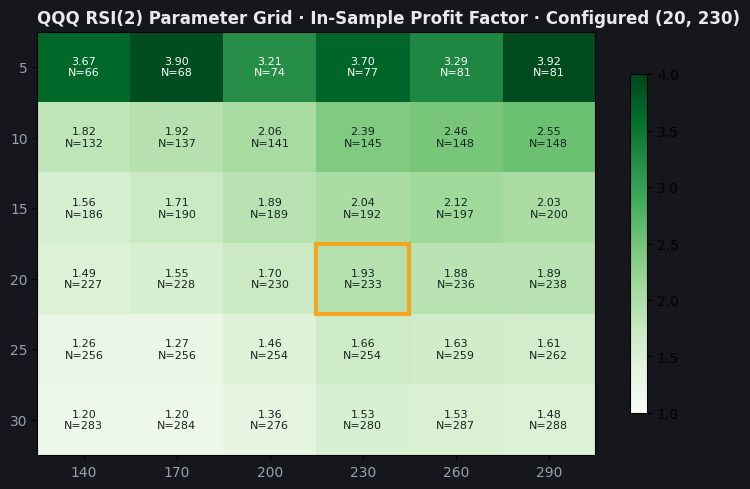

PLATEAU DIAGNOSTIC RESULTS - Baseline (15, 200):
  center_pf                : 1.8936109860442838
  plateau                  : True
  worst_neighbor_drop_pct  : 17.90980235773889
  anticliff                : True
  passed                   : True
  pct_cells_pf_ok          : 0.8888888888888888
  best_cell                : (np.int64(5), np.int64(290))
  best_pf                  : 3.9189482253864263
  edge_of_grid             : False
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : PASSED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : PASSED


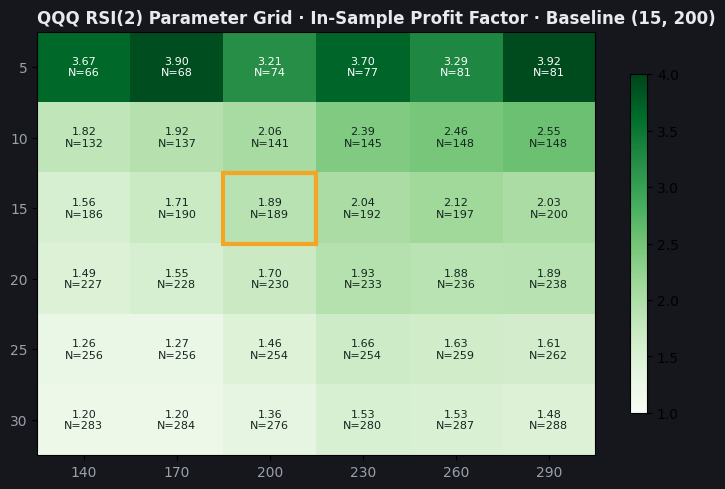

In [4]:
CHOSEN_POINTS = {
    f"Configured ({int(RSI_THR)}, {int(SMA_LEN)})": (int(RSI_THR), int(SMA_LEN)),
}
if (int(RSI_THR), int(SMA_LEN)) != (15, 200):
    CHOSEN_POINTS["Baseline (15, 200)"] = (15, 200)

checks = {}
for label, pt in CHOSEN_POINTS.items():
    check = plateau_check(pf_grid, n_grid, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
    checks[label] = check

    print("=" * 70)
    print(f"PLATEAU DIAGNOSTIC RESULTS - {label}:")
    print("=" * 70)
    for k, v in check.items():
        print(f"  {k:<25}: {v}")
    print("=" * 70)
    print(f"Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : {'PASSED' if check['plateau'] else 'FAILED'}")
    print(f"Anti-Cliff Condition (Worst neighbor drop <= 30%)        : {'PASSED' if check['anticliff'] else 'FAILED'}")
    print(f"Overall Plateau Verdict                                   : {'PASSED' if check['passed'] else 'FAILED'}")
    print("=" * 70)

    plot_grid(pf_grid, n_grid, chosen=pt,
                title=f"{TICKER} RSI(2) Parameter Grid · In-Sample Profit Factor · {label}",
                vmin=1.0, vmax=4.0)


## 4. 4D MULTI-SCENARIO ROBUSTNESS (3 EXITS X 2 COST LEVELS = 6 GRIDS)

4D MULTI-SCENARIO GRID RESULTS
Total Parameter Combinations Tested : 216
Combinations with PF >= 1.3         : 83.8% (181 / 216)
Combinations with PF >= 1.0         : 99.5% (215 / 216)
Minimum Profit Factor Across Grids  : 0.99
Median Profit Factor Across Grids   : 1.66
Maximum Profit Factor Across Grids  : 3.98
Chosen Config PF (20, 230, 2G, 5bps): 1.929
Percentile of Chosen Configuration  : 67.6%


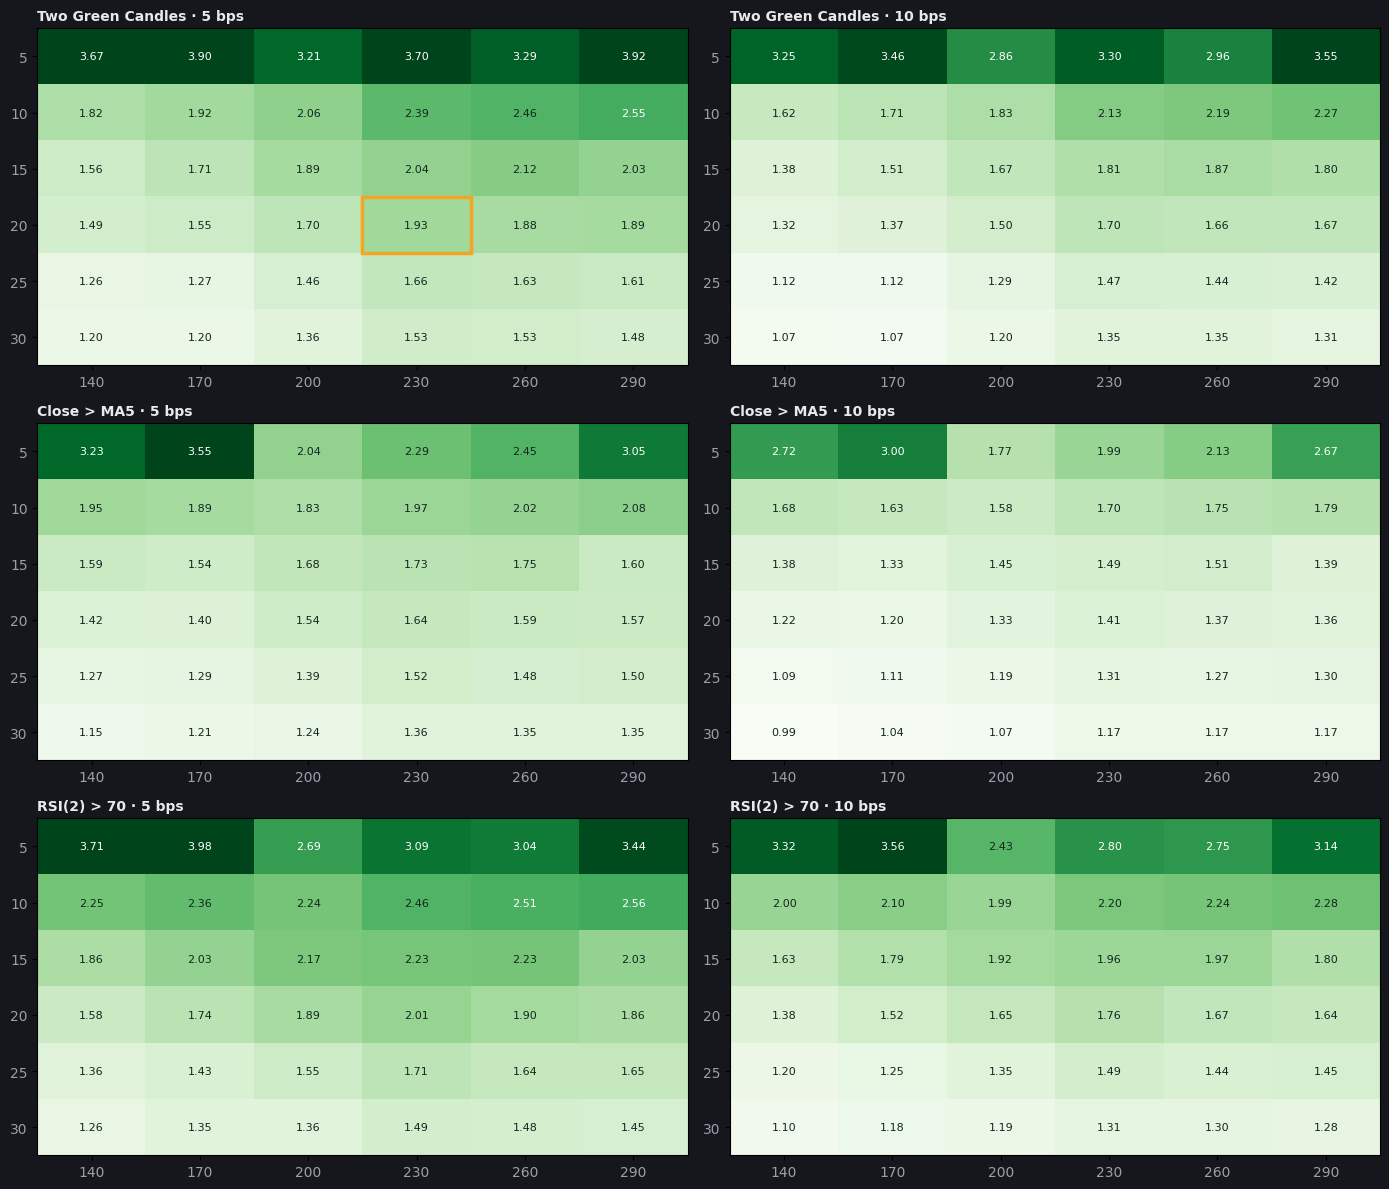

In [5]:
exits = [('2green', 'Two Green Candles'), ('ma5', 'Close > MA5'), ('rsi70', 'RSI(2) > 70')]
costs = [(5.0, '5 bps'), (10.0, '10 bps')]

all_combos = []
grid_results = {}

for exit_code, exit_label in exits:
    for slip_val, slip_label in costs:
        grid_key = f"{exit_label} · {slip_label}"
        pf_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        n_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=int)
        
        for rsi in rsi_values:
            for sma in sma_values:
                d = is_dfs[sma]
                trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=exit_code, slip_bps_per_side=slip_val)
                if len(trades) > 0:
                    p = trades['pnl'].values
                    g, l = p[p > 0].sum(), -p[p < 0].sum()
                    pf = float(g / l) if l > 0 else np.inf
                else:
                    pf = 0.0
                n = len(trades)
                pf_sub.loc[rsi, sma] = pf
                n_sub.loc[rsi, sma] = n
                
                all_combos.append({
                    'exit': exit_label, 'cost': slip_label, 'rsi': rsi, 'sma': sma,
                    'pf': pf, 'n': n
                })
        grid_results[grid_key] = pf_sub

combos_df = pd.DataFrame(all_combos)
pfs = combos_df['pf'].values

pct_pf13 = (pfs >= 1.3).mean() * 100.0
pct_pf10 = (pfs >= 1.0).mean() * 100.0
min_pf = pfs.min()
med_pf = np.median(pfs)
max_pf = pfs.max()

chosen_pf = combos_df.loc[
    (combos_df['exit'] == 'Two Green Candles') &
    (combos_df['cost'] == '5 bps') &
    (combos_df['rsi'] == int(RSI_THR)) &
    (combos_df['sma'] == int(SMA_LEN)), 'pf'
].values[0]

percentile_chosen = (pfs < chosen_pf).mean() * 100.0

print("=" * 70)
print("4D MULTI-SCENARIO GRID RESULTS")
print("=" * 70)
print(f"Total Parameter Combinations Tested : {len(combos_df)}")
print(f"Combinations with PF >= 1.3         : {pct_pf13:.1f}% ({int((pfs >= 1.3).sum())} / {len(combos_df)})")
print(f"Combinations with PF >= 1.0         : {pct_pf10:.1f}% ({int((pfs >= 1.0).sum())} / {len(combos_df)})")
print(f"Minimum Profit Factor Across Grids  : {min_pf:.2f}")
print(f"Median Profit Factor Across Grids   : {med_pf:.2f}")
print(f"Maximum Profit Factor Across Grids  : {max_pf:.2f}")
print(f"Chosen Config PF ({int(RSI_THR)}, {int(SMA_LEN)}, 2G, 5bps): {chosen_pf:.3f}")
print(f"Percentile of Chosen Configuration  : {percentile_chosen:.1f}%")
print("=" * 70)

# Display Grid Comparisons by Exit and Cost
fig, axes = plt.subplots(3, 2, figsize=(14, 12), facecolor='#15171c')
for idx, (title, grid_df) in enumerate(grid_results.items()):
    r, c = idx // 2, idx % 2
    ax = axes[r, c]
    ax.set_facecolor('#1b1e26')
    im = ax.imshow(grid_df.values, cmap='Greens', vmin=1.0, vmax=3.5, aspect='auto')
    ax.set_xticks(range(len(sma_values)))
    ax.set_xticklabels(sma_values, color='#9aa0ab')
    ax.set_yticks(range(len(rsi_values)))
    ax.set_yticklabels(rsi_values, color='#9aa0ab')
    ax.set_title(title, color='#e8e9ec', fontweight='bold', fontsize=10, loc='left')
    for i in range(len(rsi_values)):
        for j in range(len(sma_values)):
            val = grid_df.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8,
                    color='white' if val > 2.5 else '#132620')
    if "Two Green Candles" in title and "5 bps" in title:
        ia, ib = rsi_values.index(int(RSI_THR)), sma_values.index(int(SMA_LEN))
        ax.add_patch(plt.Rectangle((ib - 0.5, ia - 0.5), 1, 1, fill=False, ec='#f5a524', lw=2.5))

plt.tight_layout()
plt.show()

In [6]:
for label, (r, s) in CHOSEN_POINTS.items():
    pf_pt = combos_df.loc[
        (combos_df['exit'] == 'Two Green Candles') & (combos_df['cost'] == '5 bps') &
        (combos_df['rsi'] == r) & (combos_df['sma'] == s), 'pf'
    ].values[0]
    print(f"{label:<22}: PF = {pf_pt:.3f} | percentile among {len(combos_df)} combinations = {(pfs < pf_pt).mean()*100:.1f}%")


Configured (20, 230)  : PF = 1.929 | percentile among 216 combinations = 67.6%
Baseline (15, 200)    : PF = 1.894 | percentile among 216 combinations = 65.7%


## 5. CONCLUSION & OPTIMIZATION FINDINGS

In [7]:
print("=" * 70)
print("CONCLUSIONS (computed from notebook results)")
print("=" * 70)
for label, chk in checks.items():
    print(f"{label}: center PF {chk['center_pf']:.3f} | worst neighbor -{chk['worst_neighbor_drop_pct']:.1f}% | "
          f"plateau {'PASS' if chk['plateau'] else 'FAIL'} | anti-cliff {'PASS' if chk['anticliff'] else 'FAIL'} | "
          f"edge of grid: {chk['edge_of_grid']}")
print(f"4D: {pct_pf13:.1f}% of {len(combos_df)} combinations with PF >= 1.3 "
      f"({int((pfs >= 1.3).sum())}/{len(combos_df)}), {pct_pf10:.1f}% with PF >= 1.0, "
      f"min {min_pf:.2f}, median {med_pf:.2f}, max {max_pf:.2f}")


CONCLUSIONS (computed from notebook results)
Configured (20, 230): center PF 1.929 | worst neighbor -24.4% | plateau PASS | anti-cliff PASS | edge of grid: False
Baseline (15, 200): center PF 1.894 | worst neighbor -17.9% | plateau PASS | anti-cliff PASS | edge of grid: False
4D: 83.8% of 216 combinations with PF >= 1.3 (181/216), 99.5% with PF >= 1.0, min 0.99, median 1.66, max 3.98


In [8]:
# Save the results of this notebook for the variant
pd.DataFrame(pf_grid).to_csv(RUN_DIR / "02_pf_grid.csv")
pd.DataFrame(n_grid).to_csv(RUN_DIR / "02_n_grid.csv")

save_json(cfg, "02_optimization.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params_tested": {"rsi_thr": RSI_THR, "sma_len": SMA_LEN, "exit_mode": EXIT_MODE},
    "is_end_date": str(is_end_date.date()),
    "n_is_bars": int(n_is),
    "plateau_checks": checks,
    "grid_4d": {
        "n_combinations": int(len(combos_df)),
        "pct_pf_ge_1_3": float(pct_pf13),
        "pct_pf_ge_1_0": float(pct_pf10),
        "min_pf": float(min_pf),
        "median_pf": float(med_pf),
        "max_pf": float(max_pf),
        "chosen_pf": float(chosen_pf),
        "chosen_percentile": float(percentile_chosen),
    },
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/runs/v1_qqq/02_optimization.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/runs/v1_qqq/02_optimization.json')